In [2]:
import os
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [3]:
from tensorflow.keras.layers import Embedding,SimpleRNN,Dense
from tensorflow.keras.models import Sequential
import matplotlib.pyplot as plt

In [4]:
model_directory='models'
if not os.path.exists(model_directory):
    os.makedirs(model_directory)


In [5]:
max_features=10000
maxlen=200
embedding_size=128
rnn_size=128
batch_size=32
epochs=10

In [6]:
(x_train,y_train),(x_test,y_test)=imdb.load_data(num_words=max_features)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step


In [7]:
x_train=pad_sequences(x_train,maxlen=maxlen)

In [8]:
x_test=pad_sequences(x_test,maxlen=maxlen)

In [9]:
x_train[100]

array([   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    1,   13,
        244,    6,   87,  337,    7,  628, 2219,    5,   28,  285,   15,
        240,   93,   23,  288,  549,   18, 1455,  673,    4,  241,  534,
       3635, 8448,   20,   38,   54,   13,  258,   46,   44,   14,   13,
       1241, 7258,   12,    5,    5,   51,    9,   14,   45,    6,  762,
          7,    2, 1309,  328,    5,  428, 2473,   15,   26, 1292,    5,
       3939, 6728,    5, 1960,  279,   13,   92,  124,  803,   52,   21,
        279,   14,    9,   43,    6,  762,    7,  595,   15,   16,    2,
         23,    4, 1071,  467,    4,  403,    7,  628, 2219,    8,   97,
          6,  171, 3596,   99,  387,   72,   97,   12,  788,   15,   13,
        161,  459,   44,    4, 3939, 1101,  173,   

In [13]:
model=Sequential()
model.add(Embedding(max_features,embedding_size,input_length=maxlen))
model.add(SimpleRNN(rnn_size))
model.add(Dense(1,activation='sigmoid'))

In [14]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])

In [16]:
history=model.fit(x_train,y_train,epochs=10,batch_size=32,validation_data=(x_test,y_test))

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 132s 158ms/step - accuracy: 0.5650 - loss: 0.6720 - val_accuracy: 0.5852 - val_loss: 0.6616
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 122s 156ms/step - accuracy: 0.7034 - loss: 0.5646 - val_accuracy: 0.6572 - val_loss: 0.6079
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 145s 160ms/step - accuracy: 0.7750 - loss: 0.4710 - val_accuracy: 0.6547 - val_loss: 0.6067
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 124s 159ms/step - accuracy: 0.7562 - loss: 0.4911 - val_accuracy: 0.6467 - val_loss: 0.6345
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 125s 160ms/step - accuracy: 0.7900 - loss: 0.4484 - val_accuracy: 0.6408 - val_loss: 0.6395
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 110s 141ms/step - accuracy: 0.7983 - loss: 0.4345 - val_accuracy: 0.6745 - val_loss: 0.7599
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 122s 156ms/step - accuracy: 0.8340 - loss: 0.3821 - val_accuracy: 0.7235 - val_loss: 0.6322
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 153s 195ms/step - accuracy: 0.8277 -

In [15]:
loss,accuracy=model.evaluate(x_test,y_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 38s 44ms/step - accuracy: 0.4945 - loss: 0.7006


In [17]:
print(loss)
print(accuracy)

0.7005695104598999
0.4944800138473511


Text(0, 0.5, 'Epochs')

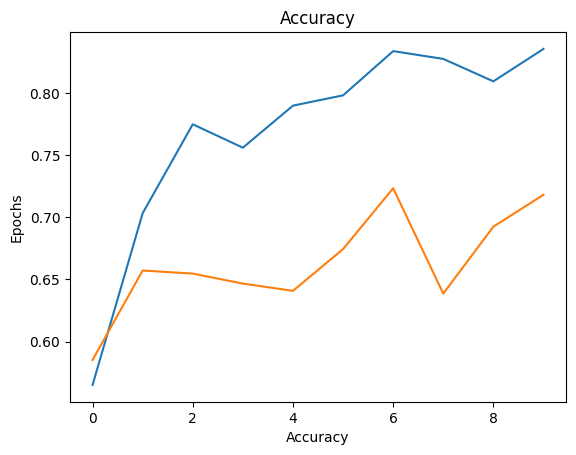

In [18]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Accuracy')
plt.xlabel('Accuracy')
plt.ylabel('Epochs')
plt.legend(loc='upper left')
plt.show()

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss')
plt.xlabel('Loss')
plt.ylabel('Epochs')
plt.legend(loc='upper left')
plt.show()